# Exoplanet Transit Detection (Kepler): Walkthrough

This notebook walks through the project end to end on **cached data**: it downloads nothing
and retrains nothing, so it runs in about a minute. Each section corresponds to an objective
in the project brief.

1. Data retrieval and provenance
2. Labels and modelling sample
3. Leakage audit: every column, and how much the leaked columns inflate results
4. Splits grouped by host star, with the disjointness assertion
5. Light-curve views and the period check
6. Models
7. Precision-recall evaluation, success criteria and the operating point
8. False-positive analysis
9. Class weighting

**What a score means.** The models reproduce a *vetting judgement*: a high score says the
signal resembles KOIs that were confirmed, and is worth follow-up. It is not a planet
detection; confirmation requires follow-up observation.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.metrics import average_precision_score, precision_recall_curve

from exoplanet.config import load_config
from exoplanet.data.catalogue import load_koi_catalogue
from exoplanet.data.labels import LABEL, PARAMETER_PROVENANCE, label_catalogue
from exoplanet.data.splits import FOLD, KOI, SPLIT, TEST, load_splits, validate_splits
from exoplanet.features.columns import column_table
from exoplanet.features.leakage import univariate_audit
from exoplanet.features.tabular import select_features

pd.set_option("display.max_colwidth", 120)
config = load_config(None)
print("Python", sys.version.split()[0], "| repository", ROOT.name)

Python 3.12.10 | repository Exoplanet_Detection_Project


## 1. Data retrieval and provenance

The KOI cumulative table was fetched once from the NASA Exoplanet Archive TAP service and
cached; the query, time and checksum were recorded next to it. Full details:
[docs/data_card.md](../docs/data_card.md).

In [2]:
meta = json.loads((config["paths"]["raw_dir"] / "koi_cumulative.meta.json").read_text())
display(pd.Series(meta, name="value").to_frame())
catalogue = load_koi_catalogue(config)
print(f"{catalogue.shape[0]:,} KOIs x {catalogue.shape[1]} columns")
catalogue["koi_disposition"].value_counts().to_frame("KOIs")

,value
source,https://exoplanetarchive.ipac.caltech.edu/TAP/sync
query,select * from cumulative
retrieved_utc,2026-10-31T03:14:15+00:00
n_rows,9564
n_columns,153
sha256,a85348f20082d24fb14d4a05a9a44c644b801998fad7cec36f8980eb1f0a69ab


9,564 KOIs x 153 columns


,KOIs
koi_disposition,
FALSE POSITIVE,4839
CONFIRMED,2748
CANDIDATE,1977


## 2. Labels and modelling sample

CONFIRMED = 1, FALSE POSITIVE = 0; CANDIDATE is excluded because it has no settled answer.
KOIs with parameters from older pipeline deliveries are dropped: they are almost all false
positives, so keeping them would teach the model delivery history instead of astrophysics.

In [3]:
all_labelled = label_catalogue(catalogue, {**config, "sample": {}})
sample = label_catalogue(catalogue, config)
prov = pd.crosstab(all_labelled[PARAMETER_PROVENANCE], all_labelled[LABEL])
prov["planet_fraction"] = (prov[1] / prov.sum(axis=1)).round(3)
display(prov)
print(f"Modelling sample: {len(sample):,} KOIs on {sample['kepid'].nunique():,} stars, "
      f"{sample[LABEL].mean():.1%} confirmed")

label,0,1,planet_fraction
koi_parm_prov,,,
q1_q16_koi,669,12,0.018
q1_q17_dr24_koi,224,5,0.022
q1_q17_dr25_koi,3946,2731,0.409


Modelling sample: 6,677 KOIs on 5,830 stars, 40.9% confirmed


## 3. Leakage audit

### 3a. Every catalogue column

Each column has a meaning, a keep-or-drop decision and a reason. `auc_value` shows how well
the column alone separates the classes (0.5 = no signal); the dropped vetting columns are
near-perfect on their own, which is exactly why they must go. The same table is in
[docs/leakage_columns.md](../docs/leakage_columns.md).

In [4]:
numeric = [c for c in sample.select_dtypes("number").columns if c != LABEL]
audit = univariate_audit(sample[numeric], sample[LABEL])
columns = column_table(catalogue.columns, config["features"]["groups"], audit)
display(columns["decision"].value_counts().to_frame("columns"))
with pd.option_context("display.max_rows", 200):
    display(columns.round(3))

,columns
decision,
drop,110
keep,41
"keep (optional, off)",2


,meaning,decision,class,reason,auc_value,auc_missing
column,,,,,,
kepid,Kepler Input Catalog ID of the host star,drop,denied:identifier,Identifier or link; carries no physical information.,0.567,0.500
kepoi_name,KOI designation (KNNNNN.NN),drop,denied:identifier,Identifier or link; carries no physical information.,NaN,NaN
kepler_name,"Kepler planet name (Kepler-NNN b), assigned once a planet is confirmed",drop,denied:label,"The target, or a vetting decision/score derived from it. Present for 2,746 of 2,748 CONFIRMED and 2 of 4,839 FALSE P...",NaN,NaN
ra,Right ascension of the host star (deg),drop,denied:sky_position,Absolute sky position; risks memorising field- or CCD-specific systematics.,0.610,0.500
ra_err,Uncertainty of: right ascension of the host star (deg),drop,denied:uncertainty,"Parameter uncertainty. Uncertainties separate the classes better than the values themselves, plausibly because plane...",0.500,0.500
ra_str,"Right ascension, sexagesimal text",drop,denied:identifier,Identifier or link; carries no physical information.,NaN,NaN
dec,Declination of the host star (deg),drop,denied:sky_position,Absolute sky position; risks memorising field- or CCD-specific systematics.,0.568,0.500
dec_err,Uncertainty of: declination of the host star (deg),drop,denied:uncertainty,"Parameter uncertainty. Uncertainties separate the classes better than the values themselves, plausibly because plane...",0.500,0.500
dec_str,"Declination, sexagesimal text",drop,denied:identifier,Identifier or link; carries no physical information.,NaN,NaN


### 3b. Before and after: how much do the leaked columns inflate the result?

Same gradient-boosting model, same development folds, only the feature set changes
(`scripts/leakage_inflation.py`).

In [5]:
text = (config["paths"]["outputs_dir"] / "leakage_inflation.md").read_text(encoding="utf-8")
display(Markdown(text.split("\n", 2)[2]))

Generated by `scripts/leakage_inflation.py`. Same gradient-boosting model and parameters on the same 5342 development KOIs and host-star grouped folds; only the feature set changes. Out-of-fold scores; PR-AUC 95% intervals from 1000 host-star bootstrap resamples. The held-out test set is not used.

- `audited`: the audited catalogue features used by `tabular` (groups `['transit', 'stellar', 'centroid']`)
- `audited_plus_vetting`: plus the vetting outputs `koi_score`, `koi_fpflag_nt`, `koi_fpflag_ss`, `koi_fpflag_co`, `koi_fpflag_ec`, `koi_pdisposition`
- `audited_lc`, `audited_lc_plus_vetting`: the same pair for the transit + stellar features of `tabular_lc`, the model comparable with the light-curve CNN
- `vetting_only`: the vetting outputs alone
- `naive`: every catalogue column except the target and row identifiers (no audit)

| feature_set | features | pr_auc | ci_low | ci_high | recall_at_p95 | precision_at_r90 | fp_at_r90 |
|---|---|---|---|---|---|---|---|
| audited | 41 | 0.994 | 0.992 | 0.995 | 0.980 | 0.986 | 28 |
| audited_plus_vetting | 47 | 0.999 | 0.999 | 1.000 | 0.998 | 0.999 | 1 |
| audited_lc | 30 | 0.969 | 0.962 | 0.974 | 0.819 | 0.920 | 170 |
| audited_lc_plus_vetting | 36 | 0.999 | 0.997 | 1.000 | 0.998 | 0.999 | 1 |
| vetting_only | 6 | 0.999 | 0.996 | 1.000 | 0.998 | 0.999 | 1 |
| naive | 124 | 1.000 | 0.999 | 1.000 | 1.000 | 0.999 | 1 |

`fp_at_r90`: false positives accepted when the threshold is lowered until 90% of confirmed planets are found (thresholds set on these same scores, for comparison only).

## Inflation relative to the audited model

Paired differences on the same resampled stars.

| comparison | difference | ci_low | ci_high | p_value |
|---|---|---|---|---|
| audited_plus_vetting - audited | 0.006 | 0.004 | 0.008 | 0.000 |
| audited_lc_plus_vetting - audited_lc | 0.030 | 0.024 | 0.037 | 0.000 |
| vetting_only - audited | 0.005 | 0.002 | 0.007 | 0.000 |
| naive - audited | 0.006 | 0.004 | 0.008 | 0.000 |


## 4. Splits grouped by host star

One star can host several KOIs, and multi-KOI stars are mostly planets. Splitting by row would
put the same star on both sides. The splits are grouped by `kepid`; the cell below **asserts**
that no star contributes to more than one partition.

In [6]:
splits = load_splits(config)
test_stars = set(splits.loc[splits[SPLIT] == TEST, "kepid"])
dev_stars = set(splits.loc[splits[SPLIT] != TEST, "kepid"])
assert test_stars.isdisjoint(dev_stars), "a host star appears in both test and development"
folds_per_star = splits[splits[SPLIT] != TEST].groupby("kepid")[FOLD].nunique()
assert (folds_per_star == 1).all(), "a host star appears in more than one development fold"
validate_splits(splits, config["splits"]["n_folds"])  # the library check, which raises on any overlap
print(f"OK: {len(test_stars):,} test stars and {len(dev_stars):,} development stars are disjoint; "
      f"every development star sits in exactly one fold.")
splits.groupby([SPLIT, FOLD]).agg(kois=(KOI, "size"), stars=("kepid", "nunique"),
                                  planet_fraction=(LABEL, "mean")).round(3)

OK: 1,160 test stars and 4,670 development stars are disjoint; every development star sits in exactly one fold.


kois  stars  planet_fraction
split fold                              
dev    0    1068    933            0.409
       1    1068    933            0.409
       2    1068    933            0.409
       3    1068    935            0.409
       4    1070    936            0.408
test  -1    1335   1160            0.409

## 5. Light-curve views and the period check

Each star's long-cadence PDCSAP light curve is detrended with a moving median (every known
transit masked), folded on the catalogue period and binned into a **global view** (whole
orbit, 2,001 bins) and a **local view** (±2 transit durations, 201 bins). The secondary view
(phase 0.5, on the local view's scale) shows eclipsing binaries.

Views for 6,665 of 6,677 KOIs (99.8%)


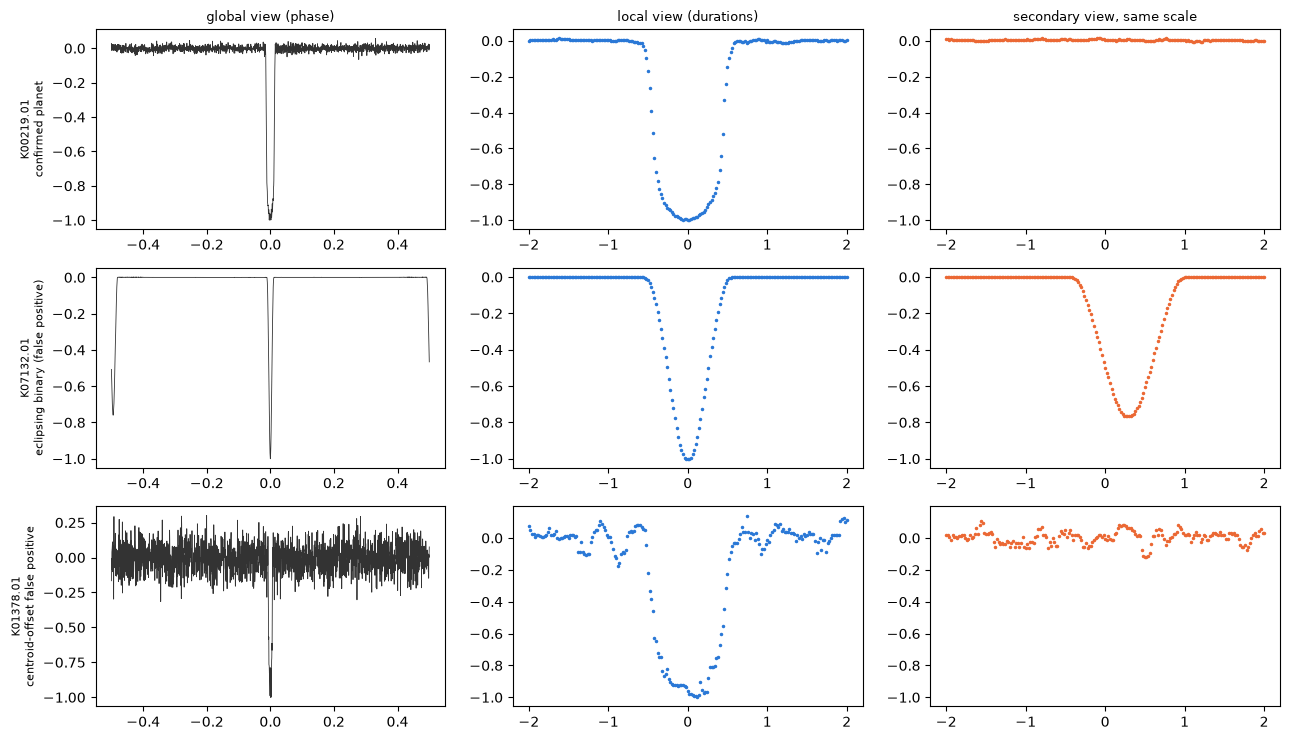

In [7]:
from exoplanet.data.lightcurves import load_views
from exoplanet.features.lightcurve import view_transit_snr

views = load_views(config, splits[KOI])
print(f"Views for {len(views):,} of {len(splits):,} KOIs ({len(views) / len(splits):.1%})")
examples = {"K00219.01": "confirmed planet", "K07132.01": "eclipsing binary (false positive)",
            "K01378.01": "centroid-offset false positive"}
fig, axes = plt.subplots(len(examples), 3, figsize=(13, 7.5))
for row, (koi, what) in zip(axes, examples.items()):
    v = views.loc[koi]
    row[0].plot(np.linspace(-0.5, 0.5, len(v["global_view"])), v["global_view"], lw=0.6, color="0.2")
    row[1].plot(np.linspace(-2, 2, len(v["local_view"])), v["local_view"], ".", ms=3, color="#2a78d6")
    row[2].plot(np.linspace(-2, 2, len(v["secondary_view"])), v["secondary_view"], ".", ms=3, color="#eb6834")
    row[2].set_ylim(row[1].get_ylim())
    row[0].set_ylabel(f"{koi}\n{what}", fontsize=8)
for ax, title in zip(axes[0], ["global view (phase)", "local view (durations)", "secondary view, same scale"]):
    ax.set_title(title, fontsize=9)
fig.tight_layout()

**Period check.** Folding on a wrong period smears the transits, so the centre of the local
view loses its dip. `view_transit_snr` measures that dip against the out-of-transit scatter;
views below 3 are flagged.

In [8]:
snr = views["local_view"].map(lambda v: view_transit_snr(np.asarray(v), config["views"]["local_durations"]))
check = pd.DataFrame({"view_snr": snr, LABEL: splits.set_index(KOI).loc[views.index, LABEL]})
check["flagged"] = check["view_snr"] < 3
display(check.groupby(LABEL).agg(kois=("flagged", "size"), flagged=("flagged", "sum"),
                                 median_view_snr=("view_snr", "median")).round(1))
flagged_fp = sample.set_index(KOI).loc[check.index[check.flagged & (check[LABEL] == 0)]]
print(f"{len(flagged_fp)} flagged false positives, {int(flagged_fp['koi_fpflag_nt'].sum())} with the "
      "not-transit-like flag: signals that never were coherent transits.")

,kois,flagged,median_view_snr
label,,,
0,3940,184,43.9
1,2725,6,18.8


184 flagged false positives, 155 with the not-transit-like flag: signals that never were coherent transits.


## 6. Models

| Model | Inputs | Notes |
|---|---|---|
| `tabular` | 41 audited catalogue features: transit, stellar, centroid | Histogram gradient boosting |
| `tabular_lc` | 30 transit + stellar features | No pixel (centroid) data, like the CNN |
| `tabular_lc_sub` | as `tabular_lc` | Trained only on the CNN's original 21% of dev KOIs |
| `cnn` | global + local views | Two-tower 1D CNN, trained on 21% of dev KOIs (test-scored) |
| `cnn_full` | global + local views | Same CNN, trained on all dev KOIs (dev only) |

All share the same host-star folds. Out-of-fold PR-AUC on the development folds:

In [9]:
rows = {}
for name in ["tabular", "tabular_lc", "tabular_lc_sub", "cnn", "cnn_full"]:
    oof = pd.read_csv(config["paths"]["outputs_dir"] / f"{name}_oof.csv")
    rows[name] = {"dev_kois": len(oof), "pooled_pr_auc": average_precision_score(oof[LABEL], oof["score"])}
pd.DataFrame(rows).T.round(3)

,dev_kois,pooled_pr_auc
tabular,5342.0,0.994
tabular_lc,5342.0,0.969
tabular_lc_sub,1123.0,0.931
cnn,1123.0,0.917
cnn_full,5331.0,0.946


## 7. Evaluation

### 7a. Precision-recall curves with bootstrap confidence bands

Bands are 95% intervals from 1,000 resamples of host stars. The held-out test set was scored
once, after all modelling decisions.

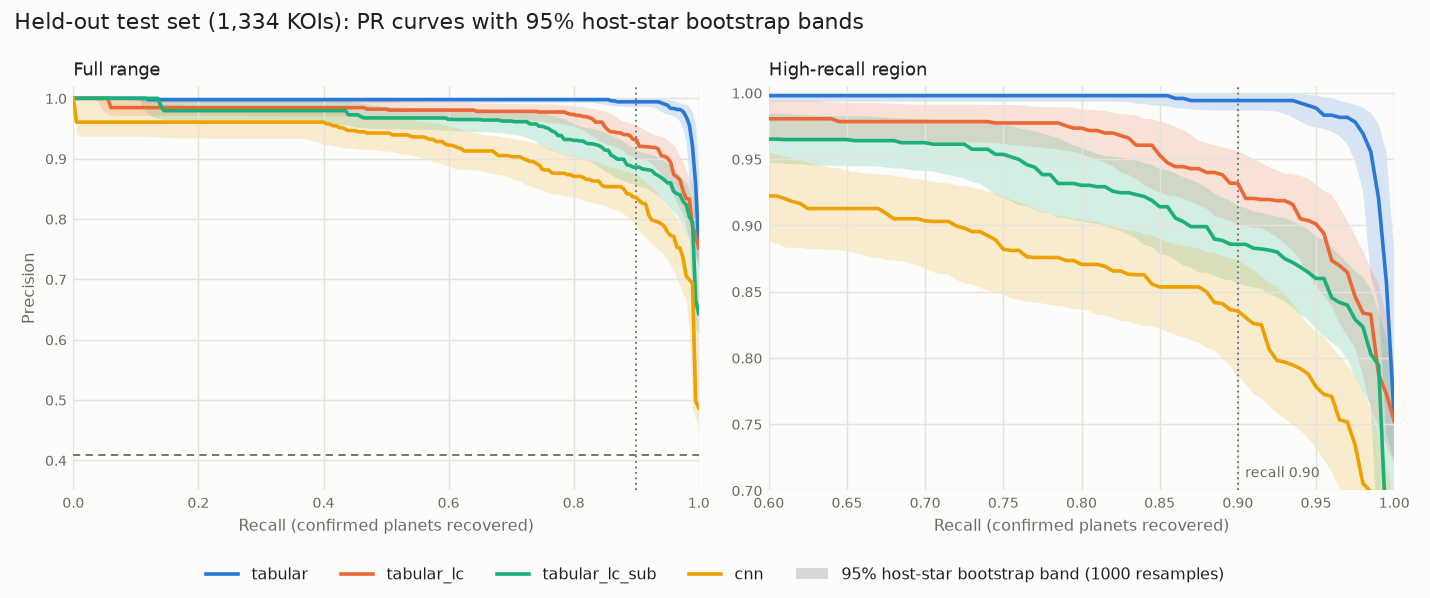

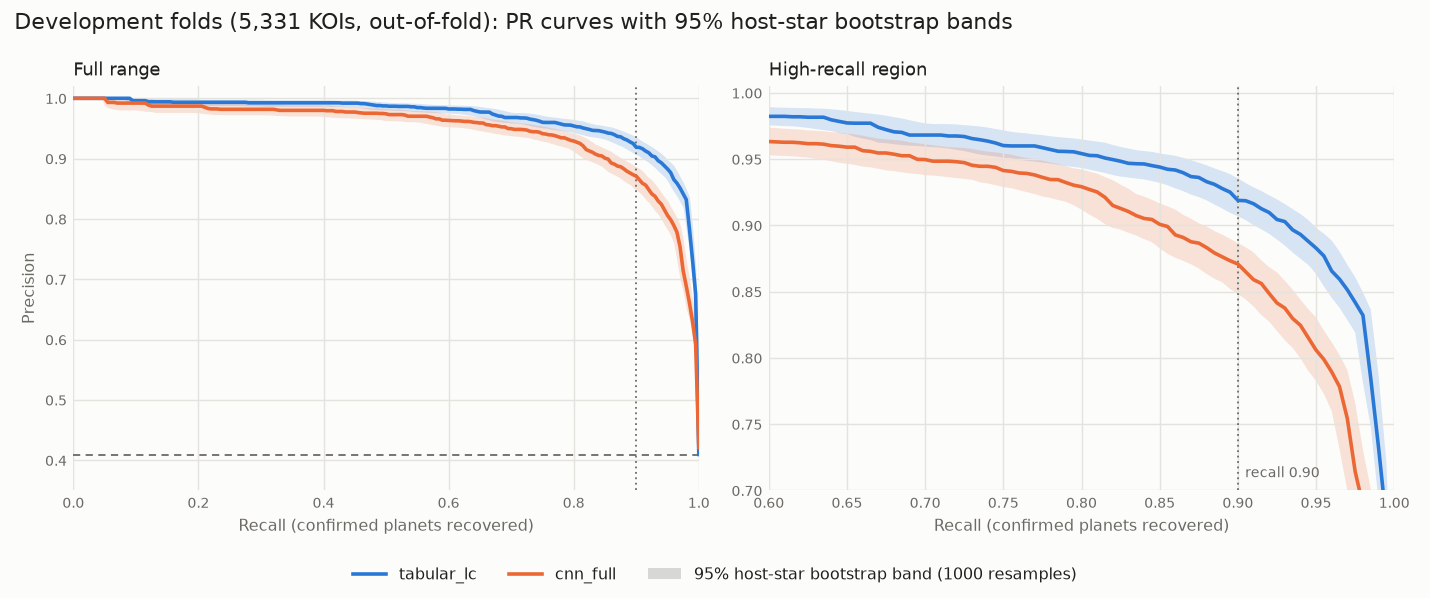

In [10]:
display(Image(filename="docs/figures/pr_bands_test.png", width=900))
display(Image(filename="docs/figures/pr_bands_dev_full.png", width=900))

### 7b. Success criteria: PR-AUC >= 0.80 and recall >= 0.90 at a stated precision

The recall-0.90 threshold is chosen on development scores and applied unchanged to the saved
test scores, so test recall lands near 0.90 rather than exactly on it.

In [11]:
from exoplanet.evaluation.pr import threshold_at_recall  # same rule as scripts/operating_points.py

out = config["paths"]["outputs_dir"]
oof = {m: pd.read_csv(out / f"{m}_oof.csv", index_col=KOI)
       for m in ["tabular", "tabular_lc", "tabular_lc_sub", "cnn", "cnn_full"]}
# Thresholds for the full-data models are set on the dev KOIs all three score (as in
# outputs/operating_points.md); the 21%-subset models use their own dev KOIs.
common = sorted(set(oof["tabular"].index) & set(oof["tabular_lc"].index) & set(oof["cnn_full"].index))
test = pd.read_csv(out / "evaluation_test_scores.csv")
rows = {}
for name in ["tabular", "tabular_lc", "tabular_lc_sub", "cnn"]:
    d = oof[name].loc[common] if name in ("tabular", "tabular_lc") else oof[name]
    thr = threshold_at_recall(d[LABEL].to_numpy(), d["score"].to_numpy(), 0.90)
    y, s = test[LABEL].to_numpy(), test[name].to_numpy()
    pred = s >= thr
    rows[name] = {"test_pr_auc": average_precision_score(y, s),
                  "test_precision": (pred & (y == 1)).sum() / pred.sum(),
                  "test_recall": (pred & (y == 1)).sum() / y.sum()}
criteria = pd.DataFrame(rows).T
criteria["pr_auc_ok"] = criteria["test_pr_auc"] >= 0.80
criteria.round(3)

,test_pr_auc,test_precision,test_recall,pr_auc_ok
tabular,0.993,0.994,0.916,True
tabular_lc,0.966,0.932,0.901,True
tabular_lc_sub,0.953,0.876,0.929,True
cnn,0.903,0.848,0.881,True


### 7c. Operating point in follow-up terms

Every false positive sent on wastes follow-up telescope time. The chosen operating point is
**precision 0.95** (about one wasted follow-up per 19 planets); the table shows what the
recall-0.90 alternative would cost.

In [12]:
text = (config["paths"]["outputs_dir"] / "operating_points.md").read_text(encoding="utf-8")
display(Markdown(text.split("## Development folds", 1)[1].split("## Held-out", 1)[0]))



|  | model | target | threshold | precision | recall | planets_found | planets_missed | wasted_followups | followups_per_planet |
|---|---|---|---|---|---|---|---|---|---|
| 0 | tabular | precision 0.99 | 0.975 | 0.990 | 0.857 | 1867 | 312 | 18 | 1.010 |
| 1 | tabular | precision 0.95 | 0.227 | 0.950 | 0.980 | 2135 | 44 | 112 | 1.052 |
| 2 | tabular | precision 0.90 | 0.036 | 0.900 | 0.990 | 2158 | 21 | 239 | 1.111 |
| 3 | tabular | recall 0.90 | 0.939 | 0.986 | 0.900 | 1962 | 217 | 28 | 1.014 |
| 4 | tabular | recall 0.95 | 0.769 | 0.976 | 0.950 | 2071 | 108 | 51 | 1.025 |
| 5 | tabular_lc | precision 0.99 | 0.976 | 0.990 | 0.475 | 1034 | 1145 | 10 | 1.010 |
| 6 | tabular_lc | precision 0.95 | 0.840 | 0.950 | 0.818 | 1782 | 397 | 93 | 1.052 |
| 7 | tabular_lc | precision 0.90 | 0.468 | 0.900 | 0.932 | 2030 | 149 | 225 | 1.111 |
| 8 | tabular_lc | recall 0.90 | 0.640 | 0.919 | 0.900 | 1962 | 217 | 174 | 1.089 |
| 9 | tabular_lc | recall 0.95 | 0.338 | 0.883 | 0.950 | 2071 | 108 | 275 | 1.133 |
| 10 | cnn_full | precision 0.99 | 0.985 | 0.992 | 0.115 | 251 | 1928 | 2 | 1.008 |
| 11 | cnn_full | precision 0.95 | 0.831 | 0.950 | 0.694 | 1512 | 667 | 79 | 1.052 |
| 12 | cnn_full | precision 0.90 | 0.557 | 0.900 | 0.854 | 1861 | 318 | 206 | 1.111 |
| 13 | cnn_full | recall 0.90 | 0.439 | 0.871 | 0.900 | 1962 | 217 | 291 | 1.148 |
| 14 | cnn_full | recall 0.95 | 0.228 | 0.806 | 0.950 | 2071 | 108 | 499 | 1.241 |



## 8. False-positive analysis

Which false positives get through? Share of false positives *rejected* at each model's
precision-0.95 threshold, by the Robovetter's flag (flags are never model inputs), on the
5,331 development KOIs both models score.

In [13]:
dev = pd.read_csv(config["paths"]["outputs_dir"] / "evaluation_dev_full_scores.csv")
thr = {"tabular_lc": 0.840, "cnn_full": 0.831}
fps = dev[dev[LABEL] == 0]
flags = {"koi_fpflag_nt": "not transit-like", "koi_fpflag_ss": "stellar eclipse",
         "koi_fpflag_co": "centroid offset", "koi_fpflag_ec": "ephemeris match"}
table = {"all false positives": {m: (fps[m] < t).mean() for m, t in thr.items()} | {"n": len(fps)}}
for col, name in flags.items():
    sub = fps[fps[col] == 1]
    table[name] = {m: (sub[m] < t).mean() for m, t in thr.items()} | {"n": len(sub)}
display(pd.DataFrame(table).T.round(3))
accepted = fps[fps["cnn_full"] >= thr["cnn_full"]]
print(f"cnn_full lets {len(accepted)} false positives through; "
      f"{int(accepted['koi_fpflag_co'].sum())} carry the centroid-offset flag, "
      f"{int(accepted['koi_fpflag_ss'].sum())} the stellar-eclipse flag.")
accepted.sort_values("cnn_full", ascending=False).head(8)[
    [KOI, "cnn_full", "koi_period", "koi_prad", "koi_model_snr", *flags]]

,tabular_lc,cnn_full,n
all false positives,0.970,0.975,3152.0
not transit-like,0.991,0.981,690.0
stellar eclipse,0.982,0.991,1712.0
centroid offset,0.946,0.964,1422.0
ephemeris match,0.956,0.970,878.0


cnn_full lets 79 false positives through; 51 carry the centroid-offset flag, 16 the stellar-eclipse flag.


,kepoi_name,cnn_full,koi_period,koi_prad,koi_model_snr,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec
1351,K01378.01,0.989802,19.301120,1.66,45.0,0,0,1,0
701,K00696.01,0.988477,7.033801,2.61,46.7,0,0,1,0
1298,K01330.02,0.984654,94.219289,2.15,37.6,0,0,1,1
210,K00242.01,0.984018,7.258450,5.53,288.6,0,0,0,0
1613,K01712.01,0.983106,10.161048,2.72,36.8,0,0,0,1
1547,K01614.01,0.981868,20.719163,1.85,8.9,0,0,0,1
1214,K01230.01,0.974977,165.739861,57.54,527.8,0,1,0,0
244,K00263.01,0.974728,20.719272,2.51,36.0,0,0,0,1


**Dominant confusing population: centroid-offset false positives.** Their light curves look
like planets because the dip is real; it just comes from a nearby star blended into the same
pixels. Photometry alone cannot reveal that, which is why the full tabular model, with
centroid diagnostics, does best. Eclipsing binaries, by contrast, are rejected well: their
V shapes and secondary eclipses are visible in the views. Missed planets are mostly faint
(low SNR) and short-period.

## 9. Class weighting

False positives outnumber planets 59:41. Both model types were also trained with identical
balanced class weights (`--class-weight balanced`) and compared on the development folds.

In [14]:
rows = {}
for base in ["tabular", "tabular_lc", "cnn_full"]:
    r = {}
    for label, name in [("unweighted", base), ("balanced", f"{base}_w")]:
        oof = pd.read_csv(config["paths"]["outputs_dir"] / f"{name}_oof.csv")
        r[label] = average_precision_score(oof[LABEL], oof["score"])
    rows[base] = r
weights = pd.DataFrame(rows).T
weights["difference"] = weights["balanced"] - weights["unweighted"]
weights.round(3)

,unweighted,balanced,difference
tabular,0.994,0.994,0.000
tabular_lc,0.969,0.967,-0.002
cnn_full,0.946,0.935,-0.011


Weighting does not help (and slightly hurts the CNN), because the imbalance is mild and the
operating threshold is chosen separately on development scores. The reported models are
unweighted, identically for both model types.

## Conclusions

- After the leakage audit, every model clears PR-AUC 0.80; both tabular models reach recall
  0.90 at precision above 0.93 on the test set.
- The leaked vetting columns alone score 0.999: a near-perfect result on this dataset means
  the audit was skipped.
- Centroid diagnostics are the most valuable information; a light-curve-only CNN cannot see
  them, and centroid-offset false positives are what fools it.
- Training data mattered more for the CNN than any input change tried: on all development
  KOIs it draws level with the matched tabular model on the earlier comparison.
- Scores are vetting judgements, not detections; follow-up observation is still required.